# GenCP seasonality demo

This notebook demonstrates how to generate synthetic GCP image chips from OSM raster maps and a season layer (winter or summer).

A test set for the demonstration is available in the folder genCP_demo/data/dataset_seasons/test . It contains OSM raster maps and reference winter and summer image patches over MGRS tile 30TXT.

GenCP HR seasonality model's weights can be downloaded [here](https://zenodo.org/records/15044428) and should be added in a "checkpoints" folder inside genCP_demo. This model has been trained on RGB images (S2 L2A TCI band) and a combination of map raster + a season encoded layer.

Generated images are saved in the data/fake_images folder. The final GenCP database (geo-referenced synthetic images) is saved in the folder "GenCP_DB".

Note: Generated images are 8 bit images.

## Installation

In [ ]:
!pip install -r requirements_HR.txt

In [1]:
import os
import random
from PIL import Image
from IPython.display import display

import matplotlib.pyplot as plt


## Visualize OSM and winter/summer reference examples

Variable **dataroot_OSM** indicates path to input OSM rasters for visualization.
Variable **dataroot_hillshades** indicates path to input hillshades rasters for visualization.

Text(0.5, 1.0, 'Winter reference')

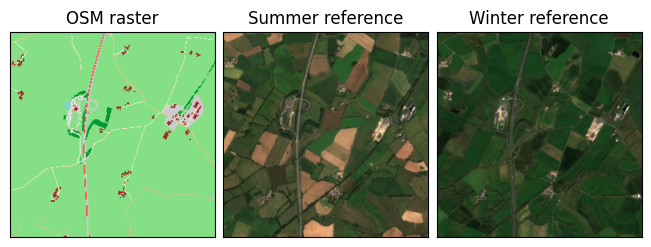

In [7]:
# path to test set
dataroot_OSM = "./data/dataset_seasons/test/A_summer"
dataroot_summer = "./data/dataset_seasons/test/B_summer"
dataroot_winter = "./data/dataset_seasons/test/B_winter"

# show test data examples
img_example = random.choice(os.listdir(dataroot_OSM))
img_patch_name = img_example[:-11]
img_winter_name = f"{img_patch_name}_winter.png"
img_osm = Image.open(os.path.join(dataroot_OSM, img_example))
img_summer = Image.open(os.path.join(dataroot_summer, img_example))
img_winter = Image.open(os.path.join(dataroot_winter, img_winter_name))

%matplotlib inline

fig, ax = plt.subplots(1,3, constrained_layout=True)
for i in range(3):
    ax[i].xaxis.set_tick_params(labelbottom=False)
    ax[i].yaxis.set_tick_params(labelleft=False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])
ax[0].imshow(img_osm)
ax[0].set_title('OSM raster')
ax[1].imshow(img_summer)
ax[1].set_title('Summer reference')
ax[2].imshow(img_winter)
ax[2].set_title('Winter reference')

## Generate images for all test samples

This section allows to generate synthetic images from OSM rasters provided as demonstration data. To generate images from your own OSM rasters / season layer, change the dataroot path. Please refer to the [data section](../README.md#data) to see guidelines on how to generate OSM rasters compatible with the model's weights provided.

Add option `--gpu_ids -1` to run on CPU if GPU is not available

* `--dataroot` indicates path to training dataset
* `--name` indicates the name the experiment/model (use "genCP_HR_hillshades_model" for demonstration)
* `--checkpoints_dir` indicates the path to checkpoints folder where model's weights are saved
* `--results_dir` indicates the path to output folder for saving generated images
* `--model` is set to "test" to indicate testing mode
* `--dataset_mode` is set to "seasonal_single" to indicate that season dataloader single mode should be used
* `--norm` is set to "batch" to indicate that batch normalization has been used during training
* `--netG` is set to "unet_256" to indicate that U-Net 256 was used as backbone for the generator during training
* `--input_nc` is set to "4" (RGB map raster are concatenated with season layer: 1 for summer, -1 for winter)
* `--output_nc` is set to "3" (generated images are RGB images)
* `--season` is set to "winter" or "summer" to specify the season of interest

In [9]:
!python ../test.py  --dataroot "./data/dataset_seasons/test" --name "genCP_HR_seasonality_model" --model "test" --results_dir "./data/fake_images_season_summer" --checkpoints_dir "./checkpoints" --dataset_mode "seasonal_single" --norm "batch" --netG "unet_256" --input_nc 4 --output_nc 3 --season "summer"

----------------- Options ---------------
             aspect_ratio: 1.0                           
               batch_size: 1                             
          checkpoints_dir: ./checkpoints                 
                crop_size: 256                           
                 dataroot: ./data/dataset_seasons/test   	[default: None]
             dataset_mode: seasonal_single               	[default: single]
                direction: AtoB                          
          display_winsize: 256                           
                    epoch: latest                        
                     eval: False                         
                  gpu_ids: 0                             
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc: 4                             
                  isTrain: False                         	[default: None]
                load_iter: 0          

In [15]:
!python ../test.py  --dataroot "./data/dataset_seasons/test/A_winter" --name "genCP_HR_seasonality_model" --model "test" --results_dir "./data/fake_images_season_winter" --checkpoints_dir "./checkpoints" --dataset_mode "seasonal_single" --norm "batch" --netG "unet_256" --input_nc 4 --output_nc 3 --season "winter"

----------------- Options ---------------
             aspect_ratio: 1.0                           
               batch_size: 1                             
          checkpoints_dir: ./checkpoints                 
                crop_size: 256                           
                 dataroot: ./data/dataset_seasons/test/A_winter	[default: None]
             dataset_mode: seasonal_single               	[default: single]
                direction: AtoB                          
          display_winsize: 256                           
                    epoch: latest                        
                     eval: False                         
                  gpu_ids: 0                             
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc: 4                             
                  isTrain: False                         	[default: None]
                load_iter: 0    

## Create GenCP database

Geo-reference generated images and save files in GenCP_DB folder.

* `-t` indicates path to generated images (not geo-referenced)
* `-i` indicates path to input test data (geo-refrenced OSM rasters)
* `-o` indicates path to output folder for geo-referenced generated images

In [12]:
!python ../gencp_georeferencing.py -t "./data/fake_images_season_summer/genCP_HR_seasonality_model/test_latest/images" -i "./data/dataset_seasons/test/A_summer" -o "./data/GenCP_DB_summer"

In [16]:
!python ../gencp_georeferencing.py -t "./data/fake_images_season_winter/genCP_HR_seasonality_model/test_latest/images" -i "./data/dataset_seasons/test/A_winter" -o "./data/GenCP_DB_winter"

## Visualize generated images

This section allows to visualize winter and summer generated images and the corresponding input OSM raster. The image displayed is choosen randomly among all generated images.

Variable **generated_dataroot** indicates path to generated images (not geo-referenced) for visualization.

Text(0.5, 1.0, 'Generated Image Winter')

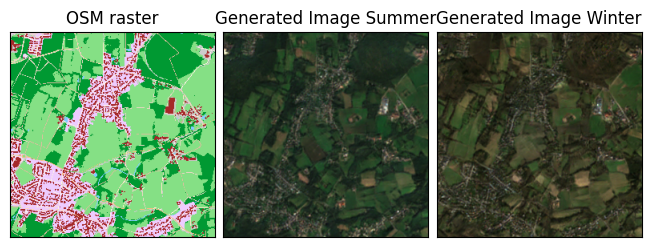

In [19]:
# path to test set
generated_summer_dataroot = "./data/fake_images_season_summer/genCP_HR_seasonality_model/test_latest/images"
generated_winter_dataroot = "./data/fake_images_season_winter/genCP_HR_seasonality_model/test_latest/images"


# select random generated image
img_example = random.choice(os.listdir(generated_summer_dataroot))
img_basename = img_example[:-16]
osm_raster_path = os.path.join(generated_summer_dataroot, img_basename + "_summer_real.png")
gen_img_summer_path = os.path.join(generated_summer_dataroot, img_basename + "_summer_fake.png")
gen_img_winter_path = os.path.join(generated_winter_dataroot, img_basename + "_winter_fake.png")

osm_img = Image.open(osm_raster_path)
gen_img_summer = Image.open(gen_img_summer_path)
gen_img_winter = Image.open(gen_img_winter_path)


%matplotlib inline

# display images
fig, ax = plt.subplots(1,3, constrained_layout=True)
for i in range(3):
    ax[i].xaxis.set_tick_params(labelbottom=False)
    ax[i].yaxis.set_tick_params(labelleft=False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])
ax[0].imshow(osm_img)
ax[0].set_title('OSM raster')
ax[1].imshow(gen_img_summer)
ax[1].set_title('Generated Image Summer')
ax[2].imshow(gen_img_winter)
ax[2].set_title('Generated Image Winter')